# **Занятие 7. Использование предобученных моделей (transfer learning)**

https://vk.com/lambda_brain


---




Разберём прикладной пример из туториалов PyTorch
https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

Проблема многих задач реального мира в том, что большие и качественные датасеты для них подобрать сложно, а сам процесс обучения с нуля занимает много времени и вычислительных ресурсов и в целом обходится весьма дорого. Да и придумать, сконструировать эффективную модель -- обычно серьёзная научная задача.

На помощь приходит **transfer learning** -- концепция, когда мы используем предобученные модели для решения схожих задач. В целом transfer learning весьма чётко отстраивается от стандартных задач машинного обучения и подразумевает различные техники корректировки уже существующих моделей. Например, популярная практика -- задействовать свёрточные сети, которые были обучены на классическом датасете ImageNet (миллион с лишним изображений, тысяча классов, http://www.image-net.org ), и немного допилить их под свою специфическую задачу.


---

Основные подходы к transfer learning такие:

-- сеть мы будем обучать не с нуля, а с уровня уже предобученной на ImageNet сети;

-- веса всей этой сети мы заморозим, и только самый последний Linear-слой с полным подключением заменим своим, и только этот слой и обучим с нуля.


---

Чему будем обучать? Например, мы хотим расширить способность нейросети распознавать муравьёв и пчёл. У нас имеется некая универсальная модель, обученная на ImageNet, и в данном случае не важно, имеются ли в ней собственные классы "муравьи" и "пчёлы" -- если они и есть, то из-за универсальности модели точность наверняка не очень высокая. Главное, что у нас есть большое основание предполагать, что эта сеть должна справиться с нашей задачей успешно, потому что её точность распознавания других подобных объектов реального мира весьма высока.

Ещё один важный нюанс в том, что у нас будет совсем небольшой оригинальный датасет -- по 120 обучающих и 75 тестовых изображений на каждый класс. С нуля качественно обучить нейросеть на таком объёме данных практически нереально.





---

Сперва нам надо локально скопировать этот небольшой датасет. Выполним соответствующие системные команды:





In [ ]:
!mkdir -p "data"
!wget -N https://download.pytorch.org/tutorial/hymenoptera_data.zip -P "data"
!unzip -o data/hymenoptera_data.zip -d data/


--2026-10-12 07:07:39--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 3.173.161.80, 3.173.161.118, 3.173.161.109, ...
Connecting to download.pytorch.org (download.pytorch.org)|3.173.161.80|:443... connected.
HTTP request sent, awaiting response... 304 Not Modified
File ‘data/hymenoptera_data.zip’ not modified on server. Omitting download.

Archive:  data/hymenoptera_data.zip
  inflating: data/hymenoptera_data/train/ants/0013035.jpg  
  inflating: data/hymenoptera_data/train/ants/1030023514_aad5c608f9.jpg  
  inflating: data/hymenoptera_data/train/ants/1095476100_3906d8afde.jpg  
  inflating: data/hymenoptera_data/train/ants/1099452230_d1949d3250.jpg  
  inflating: data/hymenoptera_data/train/ants/116570827_e9c126745d.jpg  
  inflating: data/hymenoptera_data/train/ants/1225872729_6f0856588f.jpg  
  inflating: data/hymenoptera_data/train/ants/1262877379_64fcada201.jpg  
  inflating: data/hymenoptera_data/train/ants/12

Датесет будет распакован в локальный каталог data/hymenoptera_data/

Импортируем все нужные пакеты:


In [ ]:
import copy
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms

plt.ion()

Обучающие изображения предварительно случайно модифицируем, а тестовые оставим без изменений.

In [ ]:
# Выравнивание и нормализация входных изображений
data_transforms = {
    "train": transforms.Compose(
        [
            transforms.RandomResizedCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ]
    ),
    "val": transforms.Compose(
        [
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ]
    ),
}

# загрузка двух датасетов
data_dir = "data/hymenoptera_data"
image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ["train", "val"]
}
dataloaders = {
    x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=4)
    for x in ["train", "val"]
}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print(class_names)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

['ants', 'bees']


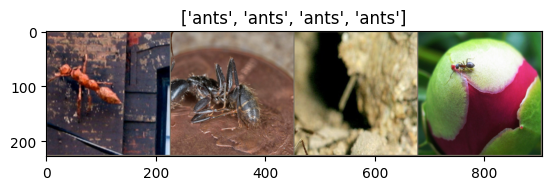

In [ ]:
# вывод изображения
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)


# выводим очередную серию изображений
inputs, classes = next(iter(dataloaders["train"]))
out = torchvision.utils.make_grid(inputs)
imshow(out, title=[class_names[x] for x in classes])

Воспользуемся в данном случае оригинальным кодом шага обучения. Из новых вещей в нём -- параметр scheduler, **планировщик скорости обучения**, которая со временем должна снижаться.

Тут применяется такое интуитивное правило: когда скорость обучения высока, то модель будет обладать слишком высокой "кинетической энергией" -- вектор не будет уходить в достаточно узкие и глубокие локальные минимумы функции потерь. Но если скорость обучения была бы очень мала, то мы наоборот постоянно попадали бы в неглубокие и совсем узкие локальные минимумы функции потерь.

In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print("Epoch {}/{}".format(epoch, num_epochs - 1))
        print("-" * 10)

        # Each epoch has a training and validation phase
        for phase in ["train", "val"]:
            if phase == "train":
                scheduler.step()
                model.train()  # Set model to training mode
            else:
                model.eval()  # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print("{} Loss: {:.4f} Acc: {:.4f}".format(phase, epoch_loss, epoch_acc))

            # deep copy the model
            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print("Training complete in {:.0f}m {:.0f}s".format(time_elapsed // 60, time_elapsed % 60))
    print("Best val Acc: {:4f}".format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

Код визуализации прогнозов для различных тестовых изображений:

In [ ]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders["val"]):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images // 2, 2, images_so_far)
                ax.axis("off")
                ax.set_title("predicted: {}".format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

Начинается основной код.

Воспользуемся готовой моделью ResNet (resnet18) с флажком pretrained, указывающим, что надо сразу использовать обученную модель, и тут же заменим её последний слой.

Настроим планировщик скорости обучения, как рекомендовано.

In [ ]:
model_ft = models.resnet18(pretrained=True)

num_ftrs = model_ft.fc.in_features  # model_ft.fc -- это слой Linear
model_ft.fc = nn.Linear(num_ftrs, 2)  # подменяем оригинальный слой своим

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Будем уменьшать скорость обучения с коэффициентом 0.1 каждые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Запустим нашу модель на переобучение.

**Предварительно укажите в настройках ноутбука поддержку GPU, иначе процесс может растянутся на десятки минут.**

In [ ]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------


/tmp/ipykernel_480/3364991941.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.4768 Acc: 0.7623
val Loss: 0.2885 Acc: 0.8758

Epoch 1/24
----------
train Loss: 0.5391 Acc: 0.7910
val Loss: 0.6149 Acc: 0.7386

Epoch 2/24
----------
train Loss: 0.4334 Acc: 0.8074
val Loss: 0.2435 Acc: 0.9216

Epoch 3/24
----------
train Loss: 0.5946 Acc: 0.7705
val Loss: 0.2114 Acc: 0.9412

Epoch 4/24
----------
train Loss: 0.3903 Acc: 0.8279
val Loss: 0.2738 Acc: 0.9085

Epoch 5/24
----------
train Loss: 0.4772 Acc: 0.7787
val Loss: 0.2908 Acc: 0.9020

Epoch 6/24
----------
train Loss: 0.3115 Acc: 0.8566
val Loss: 0.2578 Acc: 0.9085

Epoch 7/24
----------
train Loss: 0.3364 Acc: 0.8320
val Loss: 0.2480 Acc: 0.9150

Epoch 8/24
----------
train Loss: 0.2236 Acc: 0.9262
val Loss: 0.2380 Acc: 0.9281

Epoch 9/24
----------
train Loss: 0.2570 Acc: 0.8852
val Loss: 0.2422 Acc: 0.9150

Epoch 10/24
----------
train Loss: 0.3493 Acc: 0.8607
val Loss: 0.2210 Acc: 0.9346

Epoch 11/24
----------
train Loss: 0.3221 Acc: 0.8197
val Loss: 0.2993 Acc: 0.8758

Epoch 12/24
----------
t

Получим примерно такие результаты с точностью около 90-95%:

Epoch 24/24

train Loss: 0.2718 Acc: 0.9016
val Loss: 0.3111 Acc: 0.9020

Training complete in 1m 32s
Best val Acc: 0.941176

Визуально проверим, как работает наша модель:


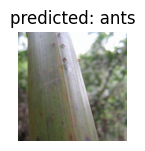

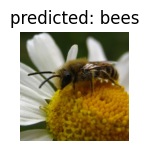

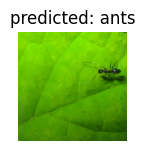

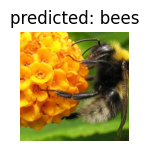

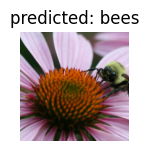

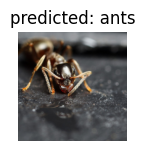

In [ ]:
visualize_model(model_ft)

Теперь посмотрим, что получится, если веса оригинальной модели предварительно заморозить. Код остаётся тем же, за исключением сбрасывания флажка модели **requires_grad** (требование вычисления градиентов) в False.

In [ ]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

Скорость обучения модели теперь будет выше, потому что для большей части сети градиенты вычисляться уже не будут.


In [ ]:
model_conv = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------


/tmp/ipykernel_480/3364991941.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.6996 Acc: 0.6516
val Loss: 0.2014 Acc: 0.9346

Epoch 1/24
----------
train Loss: 0.4233 Acc: 0.8033
val Loss: 0.2656 Acc: 0.8758

Epoch 2/24
----------
train Loss: 0.4603 Acc: 0.7869
val Loss: 0.1847 Acc: 0.9477

Epoch 3/24
----------
train Loss: 0.3096 Acc: 0.8566
val Loss: 0.1747 Acc: 0.9477

Epoch 4/24
----------
train Loss: 0.4427 Acc: 0.8156
val Loss: 0.1630 Acc: 0.9477

Epoch 5/24
----------
train Loss: 0.5505 Acc: 0.7828
val Loss: 0.1643 Acc: 0.9477

Epoch 6/24
----------
train Loss: 0.2801 Acc: 0.8730
val Loss: 0.1874 Acc: 0.9412

Epoch 7/24
----------
train Loss: 0.3882 Acc: 0.8402
val Loss: 0.1777 Acc: 0.9412

Epoch 8/24
----------
train Loss: 0.4464 Acc: 0.7951
val Loss: 0.1823 Acc: 0.9477

Epoch 9/24
----------
train Loss: 0.3421 Acc: 0.8197
val Loss: 0.1803 Acc: 0.9412

Epoch 10/24
----------
train Loss: 0.2421 Acc: 0.8934
val Loss: 0.1843 Acc: 0.9477

Epoch 11/24
----------
train Loss: 0.3131 Acc: 0.8566
val Loss: 0.1696 Acc: 0.9477

Epoch 12/24
----------
t

Получитм примерно такие результаты с точностью 90-95%:

Epoch 24/24

train Loss: 0.3331 Acc: 0.8402
val Loss: 0.1853 Acc: 0.9346

Training complete in 1m 20s
Best val Acc: 0.960784

Как видно, результат получился немного получше.


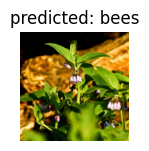

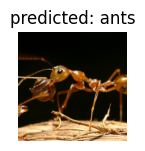

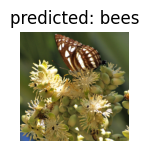

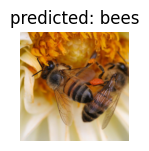

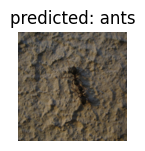

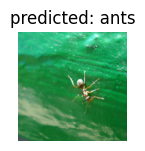

In [ ]:
visualize_model(model_conv)

plt.ioff()
plt.show()

# **Задание**

Найдите небольшой датасет, подходящий для расширения ImageNet, с классом объектов, которого в ImageNet точно нету, и дообучите готовую модель на этом датасете. Какая точность у вас получится?

---

В следующем занятии займёмся участием в соревнованиях по машинному обучению на сервисе Kaggle.

Взял спутниковые снимки однолетних и многолетних сельхозкультур EuroSat, чего нет в классах ImageNet-1K, на котором обучена ResNet18. Заменяю последний слой, потом дообучаю последний блок сети.

Датасет: https://github.com/phelber/EuroSAT

In [ ]:
import copy
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.datasets.utils import download_and_extract_archive

random_seed = 42
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

target_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", target_device)

selected_classes = ["AnnualCrop", "PermanentCrop"]
pretrained_weights = models.ResNet18_Weights.DEFAULT
imagenet_classes = pretrained_weights.meta["categories"]
assert len(imagenet_classes) == 1000
# Compare full names: "microphone" also contains the substring "crop".
imagenet_labels = {
    class_name.lower().replace(" ", "").replace("_", "").replace("-", "")
    for class_name in imagenet_classes
}
assert all(class_name.lower() not in imagenet_labels for class_name in selected_classes)

eurosat_root = Path("data/eurosat_task")
if not (eurosat_root / "eurosat" / "2750").is_dir():
    download_and_extract_archive(
        "https://huggingface.co/datasets/torchgeo/eurosat/resolve/"
        "c877bcd43f099cd0196738f714544e355477f3fd/EuroSAT.zip",
        download_root=str(eurosat_root / "eurosat"),
        filename="EuroSAT.zip",
        md5="c8fa014336c82ac7804f0398fcb19387",
    )

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)
eval_transform = pretrained_weights.transforms()
source_dataset = datasets.EuroSAT(root=str(eurosat_root), download=False)
selected_targets = {
    source_dataset.class_to_idx[class_name]: class_index
    for class_index, class_name in enumerate(selected_classes)
}


def remap_target(original_label):
    return selected_targets[original_label]


random_generator = np.random.default_rng(random_seed)
split_indices = {"train": [], "val": [], "test": []}
for class_name in selected_classes:
    original_label = source_dataset.class_to_idx[class_name]
    class_indices = np.flatnonzero(np.array(source_dataset.targets) == original_label)
    random_generator.shuffle(class_indices)
    assert len(class_indices) >= 600
    split_indices["train"].extend(class_indices[:400].tolist())
    split_indices["val"].extend(class_indices[400:500].tolist())
    split_indices["test"].extend(class_indices[500:600].tolist())

assert not set(split_indices["train"]) & set(split_indices["val"])
assert not set(split_indices["train"]) & set(split_indices["test"])
assert not set(split_indices["val"]) & set(split_indices["test"])

sample_loaders = {}
for split_name in split_indices:
    split_dataset = datasets.EuroSAT(
        root=str(eurosat_root),
        download=False,
        transform=train_transform if split_name == "train" else eval_transform,
        target_transform=remap_target,
    )
    sample_loaders[split_name] = DataLoader(
        Subset(split_dataset, split_indices[split_name]),
        batch_size=32,
        shuffle=split_name == "train",
        num_workers=0,
        pin_memory=target_device.type == "cuda",
        generator=torch.Generator().manual_seed(random_seed),
    )
    print(split_name, len(split_indices[split_name]))

Device: cuda


100%|██████████| 94.3M/94.3M [00:00<00:00, 95.2MB/s]


train 800
val 200
test 200


In [ ]:
transfer_model = models.resnet18(weights=pretrained_weights)
for parameter_value in transfer_model.parameters():
    parameter_value.requires_grad = False
transfer_model.fc = nn.Linear(transfer_model.fc.in_features, len(selected_classes))
transfer_model = transfer_model.to(target_device)
loss_function = nn.CrossEntropyLoss()


def evaluate_transfer(network_model, data_loader):
    network_model.eval()
    total_losses = 0.0
    correct_count = 0
    sample_count = 0
    with torch.no_grad():
        for image_batch, label_batch in data_loader:
            image_batch = image_batch.to(target_device)
            label_batch = label_batch.to(target_device)
            model_output = network_model(image_batch)
            total_losses += loss_function(model_output, label_batch).item() * label_batch.size(0)
            correct_count += (model_output.argmax(1) == label_batch).sum().item()
            sample_count += label_batch.size(0)
    return total_losses / sample_count, correct_count / sample_count


def fit_transfer(network_model, optimizer, epoch_count, has_unfrozen_block=False):
    best_valid_loss, _ = evaluate_transfer(network_model, sample_loaders["val"])
    best_weights = copy.deepcopy(network_model.state_dict())
    training_history = []
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)
    for epoch_index in range(epoch_count):
        # Keep the frozen backbone's BatchNorm statistics unchanged.
        network_model.eval()
        network_model.fc.train()
        if has_unfrozen_block:
            network_model.layer4.train()
        total_losses = 0.0
        sample_count = 0
        for image_batch, label_batch in sample_loaders["train"]:
            image_batch = image_batch.to(target_device)
            label_batch = label_batch.to(target_device)
            optimizer.zero_grad(set_to_none=True)
            model_output = network_model(image_batch)
            current_loss = loss_function(model_output, label_batch)
            current_loss.backward()
            optimizer.step()
            total_losses += current_loss.item() * label_batch.size(0)
            sample_count += label_batch.size(0)
        valid_loss, valid_accuracy = evaluate_transfer(network_model, sample_loaders["val"])
        scheduler.step()
        training_history.append(
            {
                "epoch": epoch_index + 1,
                "train_loss": total_losses / sample_count,
                "val_loss": valid_loss,
                "val_accuracy": valid_accuracy,
            }
        )
        print(
            f"Epoch {epoch_index + 1}/{epoch_count}: "
            f"train loss={total_losses / sample_count:.4f}, "
            f"val loss={valid_loss:.4f}, val accuracy={valid_accuracy:.1%}"
        )
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            best_weights = copy.deepcopy(network_model.state_dict())
    network_model.load_state_dict(best_weights)
    network_model.eval()
    return training_history

In [ ]:
head_optimizer = torch.optim.Adam(transfer_model.fc.parameters(), lr=1e-3)
head_history = fit_transfer(transfer_model, head_optimizer, epoch_count=3)

for parameter_value in transfer_model.layer4.parameters():
    parameter_value.requires_grad = True
finetune_optimizer = torch.optim.Adam(
    [
        {"params": transfer_model.layer4.parameters(), "lr": 1e-4},
        {"params": transfer_model.fc.parameters(), "lr": 3e-4},
    ],
    weight_decay=1e-4,
)
finetune_history = fit_transfer(
    transfer_model,
    finetune_optimizer,
    epoch_count=7,
    has_unfrozen_block=True,
)

Epoch 1/3: train loss=0.4315, val loss=0.2601, val accuracy=92.5%
Epoch 2/3: train loss=0.1810, val loss=0.1980, val accuracy=94.5%
Epoch 3/3: train loss=0.1359, val loss=0.1613, val accuracy=95.5%
Epoch 1/7: train loss=0.0931, val loss=0.0820, val accuracy=95.5%
Epoch 2/7: train loss=0.0637, val loss=0.0532, val accuracy=98.0%
Epoch 3/7: train loss=0.0624, val loss=0.0681, val accuracy=97.0%
Epoch 4/7: train loss=0.0210, val loss=0.0477, val accuracy=97.5%
Epoch 5/7: train loss=0.0209, val loss=0.0425, val accuracy=97.0%
Epoch 6/7: train loss=0.0129, val loss=0.0452, val accuracy=98.0%
Epoch 7/7: train loss=0.0166, val loss=0.0507, val accuracy=97.5%


In [ ]:
test_loss, test_accuracy = evaluate_transfer(transfer_model, sample_loaders["test"])
print(f"Test accuracy: {test_accuracy:.1%} ({len(split_indices['test'])} images)")

Test accuracy: 97.0% (200 images)
